# EDA das séries — visão de desenvolvimento (ticket #5)

**Dados:** somente a visão de desenvolvimento (`desenvolvimento.duckdb`, via `abrir_desenvolvimento`). O período OOT não é lido por nenhuma célula (ADR 0002, ticket #4).

**Status:** rascunho. Tudo abaixo é observação e interpretação pendentes de revisão; conclusões estão marcadas **PROPOSTA**.

**Regra da opção A (ticket #4):** a visão diária contém 16/08 a 18/08, dias da semana OOT de 16/08. Por isso as análises que alimentam a série semanal (sazonalidade por dia da semana, razão sexta–domingo / segunda–quinta) usam apenas as semanas completas da visão semanal (06-07 a 08-15).

**Todos os testes são exploratórios**: n pequeno (76 a 79 dias na diária, 10 semanas na semanal), escolhas feitas depois de ver os dados, sem confirmação independente. Valores-p não são prova; com 4 SKUs usa-se correção de Holm por teste.

In [1]:
import importlib.metadata as md_
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

from case_mr_health.config import Settings
from case_mr_health.diagnosticos import (
    autocorrelacao,
    bootstrap_blocos,
    estacionariedade,
    intermitencia,
    proporcao_zeros,
    razao_fim_de_semana,
    sazonalidade_semanal,
    sinalizar_outliers,
)
from case_mr_health.particoes import abrir_desenvolvimento

warnings.filterwarnings('ignore')
SEED = 20211030
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sab', 'dom']

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'pyproject.toml').is_file()
)
cfg = Settings(
    desenvolvimento_db_path=ROOT / 'data/processed/desenvolvimento.duckdb'
)
con = abrir_desenvolvimento(cfg)  # única fonte de dados deste notebook

d = con.sql(
    'SELECT sku, data, quantidade, imputado '
    'FROM serie_diaria ORDER BY sku, data'
).df()
w = con.sql(
    'SELECT sku, semana, quantidade FROM serie_semanal ORDER BY sku, semana'
).df()
part = con.sql('SELECT * FROM particao ORDER BY granularidade, sku').df()
d['data'] = pd.to_datetime(d['data'])
w['semana'] = pd.to_datetime(w['semana'])
skus = sorted(d['sku'].unique())
ydia = {s: d.loc[d['sku'] == s, 'quantidade'].to_numpy(float) for s in skus}
ysem = {s: w.loc[w['sku'] == s, 'quantidade'].to_numpy(float) for s in skus}
display(part)

,sku,granularidade,desenvolvimento_inicio,desenvolvimento_fim,oot_inicio,oot_fim
0,item A,diaria,2021-06-01,2021-08-18,2021-08-19,2021-09-01
1,item B,diaria,2021-06-04,2021-08-18,2021-08-19,2021-09-01
2,item C,diaria,2021-06-01,2021-08-18,2021-08-19,2021-09-01
3,item D,diaria,2021-06-04,2021-08-18,2021-08-19,2021-09-01
4,item A,semanal,2021-06-07,2021-08-15,2021-08-16,2021-08-29
5,item B,semanal,2021-06-07,2021-08-15,2021-08-16,2021-08-29
6,item C,semanal,2021-06-07,2021-08-15,2021-08-16,2021-08-29
7,item D,semanal,2021-06-07,2021-08-15,2021-08-16,2021-08-29


## 0. Contexto e limites da amostra

- Unidade: venda (quantidade vendida na **rede**) por SKU e período.
- Diária: 79 dias (A, C) e 76 dias (B, D); semanal: 10 semanas completas (06-07 a 08-09) para os 4 SKUs.
- Com tão poucos períodos, os testes têm baixo poder e as premissas assintóticas (ADF, KPSS, Ljung-Box, Bartlett) são aproximações. Séries de contagem com muitos zeros violam normalidade e homocedasticidade; isso é dito em cada seção.

In [2]:
# Guarda: nenhuma série ultrapassa o fim da visão de desenvolvimento
limite = part.set_index(['sku', 'granularidade'])['desenvolvimento_fim']
for s in skus:
    assert d.loc[d.sku == s, 'data'].max() <= pd.Timestamp(limite[s, 'diaria'])
    assert w.loc[w.sku == s, 'semana'].max() <= pd.Timestamp(
        limite[s, 'semanal']
    )
print('ok: séries terminam em', limite.min(), 'a', limite.max())

ok: séries terminam em 2021-08-15 00:00:00 a 2021-08-18 00:00:00


## Perguntas
1. Qual a frequência de zeros por série e granularidade (zero observado × imputado)? Os 32% a 43% da Fase 0 se mantêm?
2. Que padrão de intermitência cada série tem (ADI e CV², classes de Syntetos–Boylan–Croston)?
3. Há autocorrelação (ACF/PACF, Ljung–Box)?
4. As séries são estacionárias (ADF e KPSS)?
5. Há sazonalidade por dia da semana (testes formais)?
6. A razão ~2,4x de vendas de sexta a domingo da Fase 0 se mantém?
7. Há outliers?
8. `statsmodels` e `prophet` funcionam no Python 3.14?

## Q1 — Frequência de zeros

**Hipótese/método:** proporção de dias (semanas) com venda igual a zero, IC de 95% de Wilson. Premissa do IC: observações independentes (aqui são séries temporais com padrão semanal, então o IC é otimista). Zero imputado = dia do calendário do SKU sem venda registrada (`imputado = true`); zero observado = pedido com quantidade 0 (inexistente por construção).

In [3]:
linhas = []
for s in skus:
    y = ydia[s]
    p, lo, hi = proporcao_zeros(y)
    imp = int(d.loc[d.sku == s, 'imputado'].sum())
    obs0 = int(((d.sku == s) & (d.quantidade == 0) & (~d.imputado)).sum())
    linhas.append(
        dict(
            sku=s,
            granularidade='diaria',
            n=len(y),
            zeros=int((y == 0).sum()),
            imputados=imp,
            zeros_observados=obs0,
            proporcao=p,
            ic95_inf=lo,
            ic95_sup=hi,
        )
    )
    ys = ysem[s]
    p, lo, hi = proporcao_zeros(ys)
    linhas.append(
        dict(
            sku=s,
            granularidade='semanal',
            n=len(ys),
            zeros=int((ys == 0).sum()),
            imputados=np.nan,
            zeros_observados=np.nan,
            proporcao=p,
            ic95_inf=lo,
            ic95_sup=hi,
        )
    )
zeros_tab = pd.DataFrame(linhas)
display(zeros_tab.round(3))

,sku,granularidade,n,zeros,imputados,zeros_observados,proporcao,ic95_inf,ic95_sup
0,item A,diaria,79,34,34.0,0.0,0.430,0.327,0.540
1,item A,semanal,10,0,NaN,NaN,0.000,0.000,0.278
2,item B,diaria,76,28,28.0,0.0,0.368,0.269,0.481
3,item B,semanal,10,0,NaN,NaN,0.000,0.000,0.278
4,item C,diaria,79,36,36.0,0.0,0.456,0.350,0.565
5,item C,semanal,10,0,NaN,NaN,0.000,0.000,0.278
6,item D,diaria,76,25,25.0,0.0,0.329,0.234,0.441
7,item D,semanal,10,0,NaN,NaN,0.000,0.000,0.278


,seg,ter,qua,qui,sex,sab,dom
sku,,,,,,,
item A,0.45,0.67,0.67,0.45,0.36,0.18,0.18
item B,0.45,0.55,0.64,0.70,0.18,0.09,0.00
item C,0.91,0.50,0.58,0.45,0.18,0.27,0.27
item D,0.45,0.45,0.45,0.40,0.18,0.18,0.18


,seg,ter,qua,qui,sex,sab,dom
sku,,,,,,,
item A,11,12,12,11,11,11,11
item B,11,11,11,10,11,11,11
item C,11,12,12,11,11,11,11
item D,11,11,11,10,11,11,11


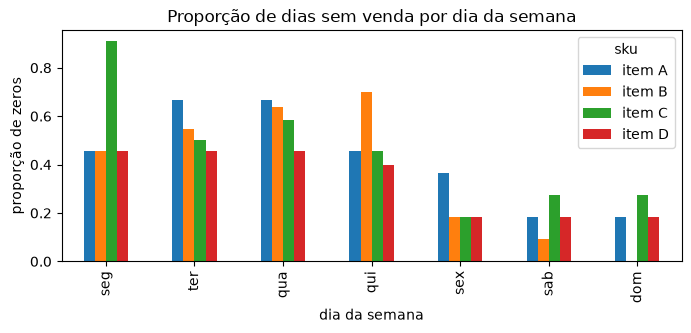

In [4]:
# Proporção de zeros por dia da semana (contagens junto com as proporções)
d['dow'] = d['data'].dt.day_of_week
por_dow = (
    d
    .assign(zero=d.quantidade == 0)
    .groupby(['sku', 'dow'])
    .agg(n=('zero', 'size'), zeros=('zero', 'sum'))
)
por_dow['prop'] = por_dow.zeros / por_dow.n
display(por_dow['prop'].unstack().set_axis(DIAS, axis=1).round(2))
display(por_dow['n'].unstack().set_axis(DIAS, axis=1))
fig, ax = plt.subplots(figsize=(8, 3))
por_dow['prop'].unstack().set_axis(DIAS, axis=1).T.plot.bar(ax=ax)
ax.set(
    title='Proporção de dias sem venda por dia da semana',
    xlabel='dia da semana',
    ylabel='proporção de zeros',
)
plt.show()

**Observação:** _pendente de aprovação do usuário._

**Interpretação:** _pendente de aprovação do usuário._

## Q2 — Intermitência (ADI e CV²)

**Método:** ADI = períodos / períodos com demanda; CV² = (desvio-padrão populacional / média)² dos tamanhos não nulos. Classes (Syntetos, Boylan e Croston, 2005): ADI < 1,32 e CV² < 0,49 suave; ADI < 1,32 e CV² ≥ 0,49 errática; ADI ≥ 1,32 e CV² < 0,49 intermitente; ADI ≥ 1,32 e CV² ≥ 0,49 irregular. Os limiares vêm da comparação de erros de Croston e da média móvel simples no trabalho original, em séries muito maiores; aqui servem como **rótulo descritivo**, não como teste.

,sku,granularidade,n,adi,cv2,classe
0,item A,diaria,79,1.76,0.20,intermitente
1,item A,semanal,10,1.00,0.13,suave
2,item B,diaria,76,1.58,0.40,intermitente
3,item B,semanal,10,1.00,0.16,suave
4,item C,diaria,79,1.84,0.30,intermitente
5,item C,semanal,10,1.00,0.30,suave
6,item D,diaria,76,1.49,0.33,intermitente
7,item D,semanal,10,1.00,0.05,suave


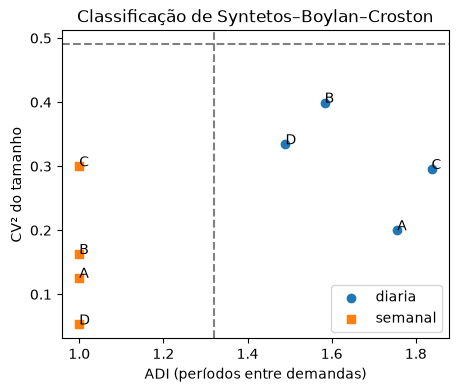

In [5]:
linhas = []
for s in skus:
    for gran, y in (('diaria', ydia[s]), ('semanal', ysem[s])):
        r = intermitencia(y)
        linhas.append(
            dict(
                sku=s,
                granularidade=gran,
                n=len(y),
                adi=r.adi,
                cv2=r.cv2,
                classe=r.classe,
            )
        )
inter = pd.DataFrame(linhas)
display(inter.round(2))
fig, ax = plt.subplots(figsize=(5, 4))
for gran, mk in (('diaria', 'o'), ('semanal', 's')):
    sub = inter[inter.granularidade == gran]
    ax.scatter(sub.adi, sub.cv2, marker=mk, label=gran)
    for _, r in sub.iterrows():
        ax.annotate(r.sku[-1], (r.adi, r.cv2))
ax.axvline(1.32, ls='--', c='gray')
ax.axhline(0.49, ls='--', c='gray')
ax.set(
    title='Classificação de Syntetos–Boylan–Croston',
    xlabel='ADI (períodos entre demandas)',
    ylabel='CV² do tamanho',
)
ax.legend()
plt.show()

**Observação:** _pendente de aprovação do usuário._

**Interpretação:** _pendente de aprovação do usuário._

## Q3 — Autocorrelação (ACF, PACF, Ljung–Box)

**Hipótese (Ljung–Box):** H0: as autocorrelações até o lag *h* são nulas. **Premissas:** estacionariedade fraca; resíduos tipo ruído sob H0; a distribuição χ² é assintótica, aproximada com n ≈ 76–79 e ruim com n = 10. Faixa de Bartlett ±1,96/√n (aproximada). A ACF de séries de contagem com muitos zeros e sazonalidade semanal mistura os dois efeitos.

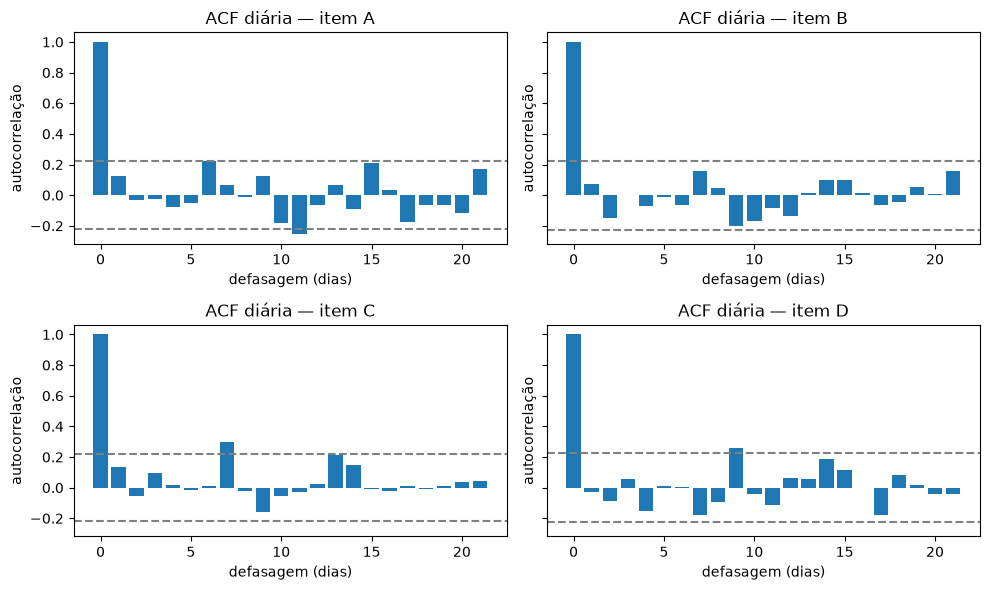

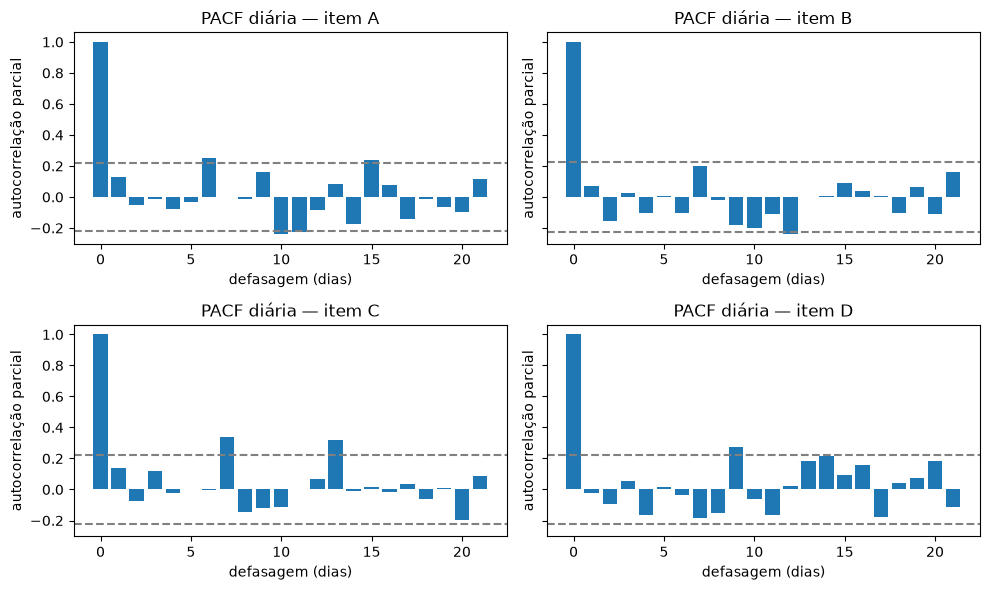

,item A,item B,item C,item D
lag1,0.12,0.07,0.13,-0.03
lag2,-0.03,-0.15,-0.05,-0.09
lag7,0.07,0.16,0.30,-0.18
lag14,-0.09,0.10,0.15,0.19
lag21,0.17,0.16,0.04,-0.04


item A ACF semanal lags 1-3: [-0.17 -0.03 -0.04] | banda ± 0.62
item B ACF semanal lags 1-3: [-0.29 -0.11  0.32] | banda ± 0.62
item C ACF semanal lags 1-3: [ 0.15  0.14 -0.26] | banda ± 0.62
item D ACF semanal lags 1-3: [ 0.09 -0.23 -0.08] | banda ± 0.62


,sku,granularidade,n,p_lag7,p_lag14,p_lag3
0,item A,diaria,79,0.432,0.155,NaN
1,item B,diaria,76,0.658,0.391,NaN
2,item C,diaria,79,0.171,0.144,NaN
3,item D,diaria,76,0.594,0.216,NaN
4,item A,semanal,10,NaN,NaN,0.933
5,item B,semanal,10,NaN,NaN,0.379
6,item C,semanal,10,NaN,NaN,0.623
7,item D,semanal,10,NaN,NaN,0.802


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
lb = []
for ax, s in zip(axes.ravel(), skus):
    r = autocorrelacao(ydia[s], nlags=21, lags_lb=[7, 14])
    ax.bar(range(len(r['acf'])), r['acf'])
    ax.axhline(r['banda'], ls='--', c='gray')
    ax.axhline(-r['banda'], ls='--', c='gray')
    ax.set(
        title=f'ACF diária — {s}',
        xlabel='defasagem (dias)',
        ylabel='autocorrelação',
    )
    lb.append(
        dict(
            sku=s,
            granularidade='diaria',
            n=len(ydia[s]),
            p_lag7=r['ljung_box_p'][7],
            p_lag14=r['ljung_box_p'][14],
        )
    )
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for ax, s in zip(axes.ravel(), skus):
    r = autocorrelacao(ydia[s], nlags=21, lags_lb=[7])
    ax.bar(range(len(r['pacf'])), r['pacf'])
    ax.axhline(r['banda'], ls='--', c='gray')
    ax.axhline(-r['banda'], ls='--', c='gray')
    ax.set(
        title=f'PACF diária — {s}',
        xlabel='defasagem (dias)',
        ylabel='autocorrelação parcial',
    )
fig.tight_layout()
plt.show()
acf_dia = {
    s: autocorrelacao(ydia[s], nlags=21, lags_lb=[7])['acf'] for s in skus
}
display(
    pd.DataFrame(
        {s: acf_dia[s][[1, 2, 7, 14, 21]] for s in skus},
        index=['lag1', 'lag2', 'lag7', 'lag14', 'lag21'],
    ).round(2)
)
# Semanal: n = 10, só lags 1 a 3 (Ljung–Box em lag 3)
for s in skus:
    r = autocorrelacao(ysem[s], nlags=3, lags_lb=[3])
    lb.append(
        dict(
            sku=s,
            granularidade='semanal',
            n=len(ysem[s]),
            p_lag3=r['ljung_box_p'][3],
        )
    )
    print(
        s,
        'ACF semanal lags 1-3:',
        np.round(r['acf'][1:], 2),
        '| banda ±',
        round(r['banda'], 2),
    )
display(pd.DataFrame(lb).round(3))

**Observação:** _pendente de aprovação do usuário._

**Interpretação:** _pendente de aprovação do usuário._

## Q4 — Estacionariedade (ADF e KPSS)

**Hipóteses:** ADF: H0 = raiz unitária. KPSS (nível): H0 = estacionária em torno de uma constante. Usar as duas evita aceitar H0 por falta de poder: se ADF rejeita e KPSS não rejeita, estacionária; o oposto indica raiz unitária; qualquer outra combinação é inconclusiva. **Premissas:** erros aproximadamente homocedásticos e sem autocorrelação residual (por isso o ADF escolhe defasagens por AIC), amostra suficiente; o ADF tem baixo poder em amostras curtas e séries de contagem com muitos zeros violam a normalidade assumida. O código exige n ≥ 30; abaixo disso o resultado é **"não testável"** (a semanal tem n = 10).

In [7]:
linhas = []
for s in skus:
    for gran, y in (('diaria', ydia[s]), ('semanal', ysem[s])):
        r = estacionariedade(y)
        linhas.append(dict(sku=s, granularidade=gran, **r))
display(pd.DataFrame(linhas).round(3))

,sku,granularidade,testavel,n,adf_p,kpss_p,veredito
0,item A,diaria,True,79,0.0,0.100,estacionária
1,item A,semanal,False,10,NaN,NaN,NaN
2,item B,diaria,True,76,0.0,0.100,estacionária
3,item B,semanal,False,10,NaN,NaN,NaN
4,item C,diaria,True,79,0.0,0.078,estacionária
5,item C,semanal,False,10,NaN,NaN,NaN
6,item D,diaria,True,76,0.0,0.100,estacionária
7,item D,semanal,False,10,NaN,NaN,NaN


**Observação:** _pendente de aprovação do usuário._

**Interpretação:** _pendente de aprovação do usuário._

## Q5 — Sazonalidade por dia da semana

**Hipótese:** H0: a distribuição da venda diária é a mesma nos 7 dias da semana. **Testes:** (a) Kruskal–Wallis com os dias agrupados (premissa: observações independentes e distribuições de mesma forma sob H0; as semanas não são independentes se houver tendência); (b) Friedman com semanas como blocos (remove o nível semanal; exige blocos completos; muitos empates por causa dos zeros); (c) permutação do rótulo do dia dentro de cada semana, estatística F de uma via (não assume normalidade; preserva a estrutura por semana). Os p-valores de cada teste recebem correção de Holm nos 4 SKUs. Usa-se só as 10 semanas completas (06-07 a 08-15).

semanas completas: 10 | de 2021-06-07 a 2021-08-15


,kruskal_p,friedman_p,permutacao_p,kruskal_p_holm,friedman_p_holm,permutacao_p_holm
item A,0.0301,0.1000,0.0517,0.0601,0.1999,0.1034
item B,0.0034,0.0014,0.0035,0.0134,0.0056,0.0140
item C,0.0170,0.0144,0.0084,0.0510,0.0432,0.0252
item D,0.1275,0.1549,0.0591,0.1275,0.1999,0.1034
rede,0.0000,0.0000,0.0001,NaN,NaN,NaN


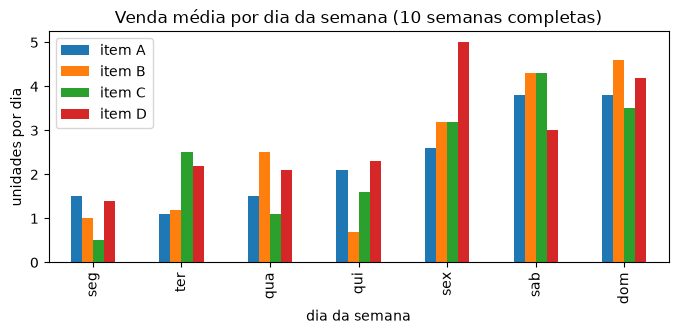

,item A,item B,item C,item D
seg,1.5,1.0,0.5,1.4
ter,1.1,1.2,2.5,2.2
qua,1.5,2.5,1.1,2.1
qui,2.1,0.7,1.6,2.3
sex,2.6,3.2,3.2,5.0
sab,3.8,4.3,4.3,3.0
dom,3.8,4.6,3.5,4.2


In [8]:
semanas = sorted(w['semana'].unique())


def matriz(df_sku):
    x = df_sku.set_index('data')['quantidade']
    return np.array(
        [
            [x[pd.Timestamp(wk) + pd.Timedelta(days=i)] for i in range(7)]
            for wk in semanas
        ],
        float,
    )


mats = {s: matriz(d[d.sku == s]) for s in skus}
mats['rede'] = sum(mats[s] for s in skus)
print(
    'semanas completas:',
    len(semanas),
    '| de',
    pd.Timestamp(semanas[0]).date(),
    'a',
    (pd.Timestamp(semanas[-1]) + pd.Timedelta(days=6)).date(),
)
res = {
    s: sazonalidade_semanal(m, n_perm=10_000, seed=SEED)
    for s, m in mats.items()
}
tab = pd.DataFrame(res).T
for col in ('kruskal_p', 'friedman_p', 'permutacao_p'):
    tab[col + '_holm'] = np.nan
    tab.loc[skus, col + '_holm'] = multipletests(
        tab.loc[skus, col].fillna(1.0), method='holm'
    )[1]
display(tab.round(4))
medias = pd.DataFrame({s: mats[s].mean(axis=0) for s in skus}, index=DIAS)
fig, ax = plt.subplots(figsize=(8, 3))
medias.plot.bar(ax=ax)
ax.set(
    title='Venda média por dia da semana (10 semanas completas)',
    xlabel='dia da semana',
    ylabel='unidades por dia',
)
plt.show()
display(medias.round(2))

**Observação:** _pendente de aprovação do usuário._

**Interpretação:** _pendente de aprovação do usuário._

## Q6 — Razão sexta–domingo / segunda–quinta (Fase 0: ~2,4x)

**Método:** média diária de sexta a domingo dividida pela de segunda a quinta, nas 10 semanas completas. IC de 95% por bootstrap percentil reamostrando **semanas** (blocos) com 10.000 repetições (seed fixa). Com 10 semanas o IC é largo e a cobertura nominal não é garantida.

In [9]:
linhas = []
for s, m in mats.items():
    est, lo, hi = bootstrap_blocos(
        m, razao_fim_de_semana, n_boot=10_000, seed=SEED
    )
    linhas.append(dict(serie=s, razao=est, ic95_inf=lo, ic95_sup=hi))
display(pd.DataFrame(linhas).round(2))

,serie,razao,ic95_inf,ic95_sup
0,item A,2.19,1.35,4.11
1,item B,2.99,2.05,5.17
2,item C,2.57,1.62,5.49
3,item D,2.03,1.27,3.28
4,rede,2.40,1.94,3.14


**Observação:** _pendente de aprovação do usuário._

**Interpretação:** _pendente de aprovação do usuário._

## Q7 — Outliers (apenas sinalização)

**Método:** entre os valores não nulos, |z robusto| = |0,6745 (x − mediana)/MAD| > 3,5 (Iglewicz e Hoaglin) e a regra de Tukey (1,5 × IQR). São **sinais para inspeção**, não critério de remoção; não há tratamento neste ticket.

In [10]:
linhas = []
for s in skus:
    datas = d.loc[d.sku == s, 'data'].reset_index(drop=True)
    for gran, y, idx_datas in (
        ('diaria', ydia[s], datas),
        (
            'semanal',
            ysem[s],
            w.loc[w.sku == s, 'semana'].reset_index(drop=True),
        ),
    ):
        r = sinalizar_outliers(y)
        linhas.append(
            dict(
                sku=s,
                granularidade=gran,
                max=y.max(),
                mad=[
                    (idx_datas[i].date().isoformat(), y[i]) for i in r['mad']
                ],
                iqr=[
                    (idx_datas[i].date().isoformat(), y[i]) for i in r['iqr']
                ],
            )
        )
display(pd.DataFrame(linhas))

,sku,granularidade,max,mad,iqr
0,item A,diaria,9.0,[],"[(2021-08-14, 9.0)]"
1,item A,semanal,25.0,[],[]
2,item B,diaria,10.0,[],[]
3,item B,semanal,29.0,[],[]
4,item C,diaria,9.0,[],[]
5,item C,semanal,40.0,"[(2021-07-19, 40.0)]","[(2021-07-19, 40.0)]"
6,item D,diaria,10.0,[],"[(2021-06-11, 10.0), (2021-07-23, 10.0)]"
7,item D,semanal,30.0,[],[]


**Observação:** _pendente de aprovação do usuário._

**Interpretação:** _pendente de aprovação do usuário._

## Q8 — Confronto com a Fase 0 e com o ADR 0003

| Fato da Fase 0 / ADR 0003 | Valor original (histórico inteiro, com OOT) | Valor na visão de desenvolvimento |
| --- | --- | --- |
| Dias sem venda por SKU | 32% a 43% | ver Q1 |
| Vendas por dia de sexta a domingo vs. demais | ~2,4x | ver Q6 |

_Preenchido após a aprovação do usuário._

## Q9 — `statsmodels` e `prophet` no Python 3.14

In [11]:
import sys

from prophet import Prophet
from statsmodels.tsa.arima.model import ARIMA

PONTOS_ESPERADOS = 67
print('Python', sys.version.split()[0])
for pkg in ('statsmodels', 'prophet', 'scipy', 'pandas'):
    print(pkg, md_.version(pkg))
print(
    'ARIMA ajusta em série sintética:',
    ARIMA(np.random.default_rng(1).normal(size=60).cumsum(), order=(1, 1, 0))
    .fit()
    .aic
    is not None,
)
m = Prophet(
    weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False
)
dfp = pd.DataFrame({
    'ds': pd.date_range('2021-06-01', periods=60),
    'y': np.random.default_rng(2).poisson(3, 60),
})
print(
    'Prophet ajusta em série sintética:',
    m.fit(dfp).predict(m.make_future_dataframe(7)).shape[0]
    == PONTOS_ESPERADOS,
)

Importing plotly failed. Interactive plots will not work.


02:44:52 - cmdstanpy - INFO - Chain [1] start processing


02:44:52 - cmdstanpy - INFO - Chain [1] done processing


Python 3.14.0
statsmodels 0.15.0
prophet 1.5.0
scipy 1.18.1
pandas 3.1.0
ARIMA ajusta em série sintética: True
Prophet ajusta em série sintética: True


**Observação:** `statsmodels` e `prophet` instalam e ajustam modelos no Python 3.14 (verificação com séries sintéticas, não com os dados do projeto). O Prophet permanece candidato (ADR 0003); a decisão de incluí-lo por série é do ticket #6.

## Resumo das observações
_Pendente de aprovação do usuário._

## Limitações
- 76 a 79 dias na diária e 10 semanas na semanal; testes de baixo poder e premissas assintóticas aproximadas.
- Séries de contagem com muitos zeros e padrão semanal: normalidade e independência dos testes são violadas.
- Os p-valores são exploratórios; a visão de desenvolvimento é a mesma usada depois no backtest.
- Venda é proxy de demanda; rupturas e dados perdidos são indistinguíveis de zeros.

## Perguntas para o usuário
_Pendente._